# 24 · Sensors: wrist force/torque, touch, accelerometer, rangefinder, joint and frame sensors

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt
from vlacourse.panda import add_ee_site, solve_ik, yaw_quat, GRIP_OPEN, GRIP_CLOSED

S, O = mujoco.mjtSensor, mujoco.mjtObj

def build():
    spec = mm.get("franka_emika_panda").spec("scene")
    add_ee_site(spec)
    spec.body("hand").add_site(name="ft", size=[0.01] * 3)
    for side in ["left", "right"]:
        spec.body(f"{side}_finger").add_site(name=f"{side}_pad", pos=[0, 0, 0.045], size=[0.012, 0.012, 0.012], type=mujoco.mjtGeom.mjGEOM_BOX, rgba=[0, 1, 0, 0.3])
    cube = spec.worldbody.add_body(name="cube", pos=[0.5, 0.0, 0.02])
    cube.add_freejoint()
    cube.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.02] * 3, mass=0.2, rgba=[0.9, 0.2, 0.2, 1], friction=[1.5, 0.01, 0.001])
    spec.add_sensor(name="wrist_force", type=S.mjSENS_FORCE, objtype=O.mjOBJ_SITE, objname="ft")
    spec.add_sensor(name="wrist_torque", type=S.mjSENS_TORQUE, objtype=O.mjOBJ_SITE, objname="ft")
    spec.add_sensor(name="left_touch", type=S.mjSENS_TOUCH, objtype=O.mjOBJ_SITE, objname="left_pad")
    spec.add_sensor(name="right_touch", type=S.mjSENS_TOUCH, objtype=O.mjOBJ_SITE, objname="right_pad")
    spec.add_sensor(name="accel", type=S.mjSENS_ACCELEROMETER, objtype=O.mjOBJ_SITE, objname="ft")
    rf = spec.add_sensor(name="range", type=S.mjSENS_RANGEFINDER, objtype=O.mjOBJ_SITE, objname="ee")
    rf.intprm[0] = 1
    spec.add_sensor(name="ee_pos", type=S.mjSENS_FRAMEPOS, objtype=O.mjOBJ_SITE, objname="ee")
    spec.add_sensor(name="cube_pos", type=S.mjSENS_FRAMEPOS, objtype=O.mjOBJ_BODY, objname="cube")
    spec.add_sensor(name="finger_pos", type=S.mjSENS_JOINTPOS, objtype=O.mjOBJ_JOINT, objname="finger_joint1")
    noisy = spec.add_sensor(name="joint4_noisy", type=S.mjSENS_JOINTPOS, objtype=O.mjOBJ_JOINT, objname="joint4")
    noisy.noise = 0.01
    model = spec.compile()
    return model, mujoco.MjData(model)

def pick_and_log(model, data):
    mujoco.mj_resetDataKeyframe(model, data, 0)
    data.qpos[9:12] = [0.5, 0, 0.02]; mujoco.mj_forward(model, data)
    q = data.qpos[:7].copy(); log, phases = [], []
    plan = [([0.5, 0, 0.15], GRIP_OPEN, "approach"), ([0.5, 0, 0.015], GRIP_OPEN, "descend"),
            ([0.5, 0, 0.015], GRIP_CLOSED, "grasp"), ([0.5, 0, 0.25], GRIP_CLOSED, "lift"), ([0.5, 0, 0.25], GRIP_CLOSED, "hold")]
    for target, grip, name in plan:
        q_goal, _ = solve_ik(model, data, np.array(target), yaw_quat(0.785), q)
        for i in range(600):
            s = min(1.0, (i + 1) / 400)
            data.ctrl[:7] = q + (q_goal - q) * (3 * s**2 - 2 * s**3); data.ctrl[7] = grip
            mujoco.mj_step(model, data)
            log.append(data.sensordata.copy()); phases.append(name)
        q = q_goal
    return np.array(log), phases

def column(model, name):
    sid = model.sensor(name).id
    a = model.sensor_adr[sid]
    return slice(a, a + model.sensor_dim[sid])

In [2]:
model, data = build()
mujoco.mj_resetDataKeyframe(model, data, 0); mujoco.mj_forward(model, data)
for i in range(model.nsensor):
    s = model.sensor(i)
    print(f"{s.name:13s} {S(model.sensor_type[i]).name:22s} dim={model.sensor_dim[i]} adr={model.sensor_adr[i]:2d} value={data.sensordata[column(model, s.name)].round(3)}")

wrist_force   mjSENS_FORCE           dim=3 adr= 0 value=[-0.081 -0.14  -0.063]
wrist_torque  mjSENS_TORQUE          dim=3 adr= 3 value=[ 0.024 -0.007  0.001]
left_touch    mjSENS_TOUCH           dim=1 adr= 6 value=[0.]
right_touch   mjSENS_TOUCH           dim=1 adr= 7 value=[0.]
accel         mjSENS_ACCELEROMETER   dim=3 adr= 8 value=[-0.063  0.397 -0.069]
range         mjSENS_RANGEFINDER     dim=1 adr=11 value=[0.521]
ee_pos        mjSENS_FRAMEPOS        dim=3 adr=12 value=[ 0.554 -0.     0.521]
cube_pos      mjSENS_FRAMEPOS        dim=3 adr=15 value=[0.5  0.   0.02]
finger_pos    mjSENS_JOINTPOS        dim=1 adr=18 value=[0.04]
joint4_noisy  mjSENS_JOINTPOS        dim=1 adr=19 value=[-1.571]


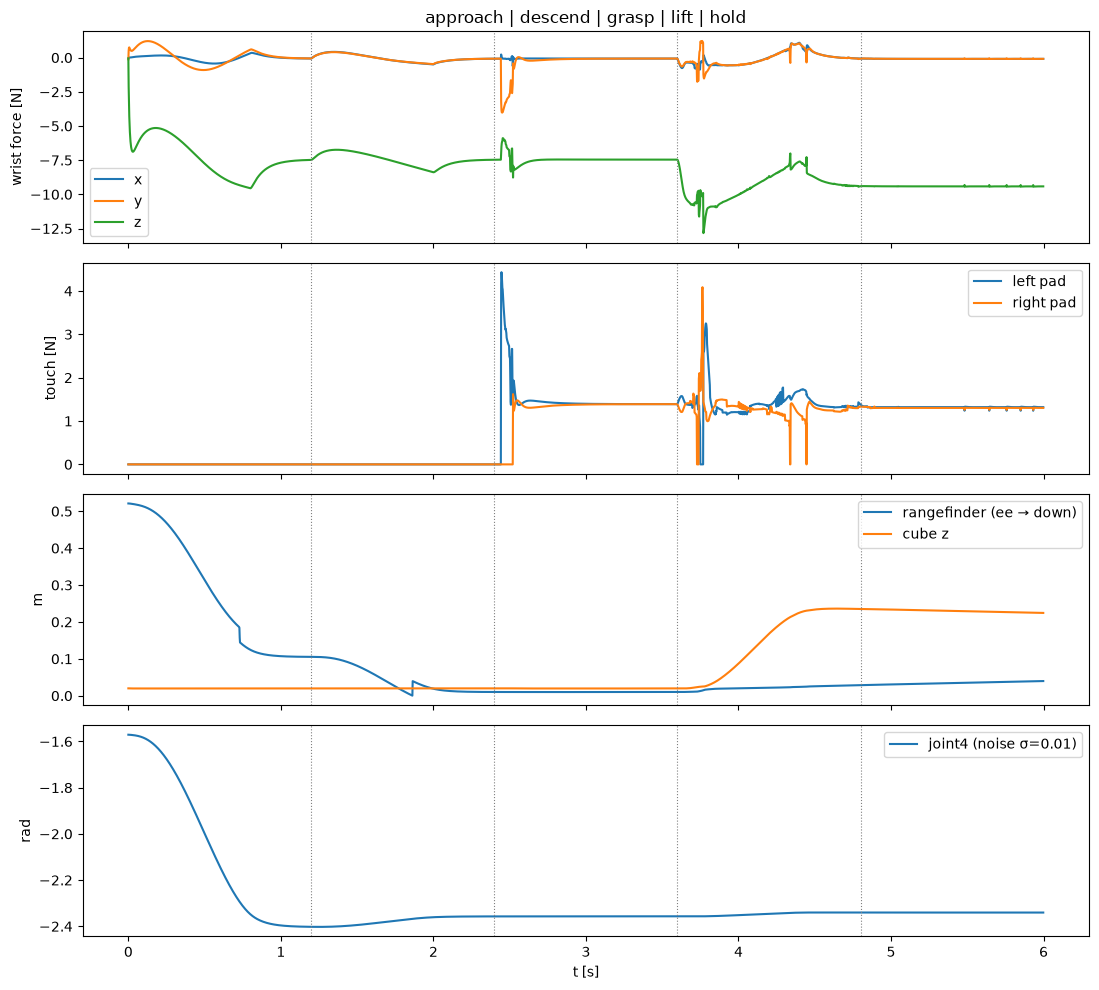

In [3]:
log, phases = pick_and_log(model, data)
t = np.arange(len(log)) * model.opt.timestep
fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
axes[0].plot(t, log[:, column(model, "wrist_force")]); axes[0].set_ylabel("wrist force [N]"); axes[0].legend(["x", "y", "z"])
axes[1].plot(t, log[:, column(model, "left_touch")], label="left pad"); axes[1].plot(t, log[:, column(model, "right_touch")], label="right pad")
axes[1].set_ylabel("touch [N]"); axes[1].legend()
axes[2].plot(t, log[:, column(model, "range")], label="rangefinder (ee → down)"); axes[2].plot(t, log[:, column(model, "cube_pos")][:, 2], label="cube z")
axes[2].set_ylabel("m"); axes[2].legend()
axes[3].plot(t, log[:, column(model, "joint4_noisy")], label="joint4 (noise σ=0.01)"); axes[3].set_ylabel("rad"); axes[3].set_xlabel("t [s]"); axes[3].legend()
for ax in axes:
    for k in range(1, 5):
        ax.axvline(k * 600 * model.opt.timestep, c="gray", ls=":", lw=0.8)
axes[0].set_title("approach | descend | grasp | lift | hold")
plt.tight_layout(); plt.show()

In [4]:
lift = np.array(phases) == "hold"
fz = log[lift][:, column(model, "wrist_force")].mean(0)
print("mean wrist force while holding the 0.2 kg cube:", fz.round(2), "N  (hand+fingers+cube weight is carried here)")
print("grasp detected (both touch > 1 N):", bool(((log[:, column(model, 'left_touch')] > 1) & (log[:, column(model, 'right_touch')] > 1)).any()))

mean wrist force while holding the 0.2 kg cube: [-0.09 -0.09 -9.41] N  (hand+fingers+cube weight is carried here)
grasp detected (both touch > 1 N): True
